In [2]:
import pandas as pd

# Load our preliminary dataset
df = pd.read_csv("powerpulse_master_v1_2024-2026.csv")

# Inspect the data
print("First five rows:")
print(df.head())

print("\nDataset dimensions:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nSummary statistics:")
print(df.describe(include="all"))

First five rows:
         date  year     month  month_num  total_generation_gwh  \
0  2024-01-01  2024   January          1               1026.49   
1  2024-02-01  2024  February          2                978.96   
2  2024-03-01  2024     March          3               1051.98   
3  2024-04-01  2024     April          4                997.79   
4  2024-05-01  2024       May          5               1023.52   

   imports_uganda_gwh  imports_ethiopia_gwh  imports_tanzania_gwh  \
0               20.29                121.96                   0.0   
1               18.13                113.35                   0.0   
2               17.43                110.97                   0.0   
3               17.99                110.91                   0.0   
4               16.38                112.49                   0.0   

   total_imports_gwh  total_generation_and_imports_gwh  kplc_sales_gwh  \
0             142.25                           1168.73          881.37   
1             131.48   

In [3]:

import pandas as pd

df = pd.read_csv("powerpulse_master_v1_2024-2026.csv")

# Convert dates into proper datetime values
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Check the main forecasting target
target = "kplc_sales_gwh"

print("\n--- POWERPULSE DATA QUALITY CHECK ---")

print("\nDataset shape:")
print(df.shape)

print("\nDate range:")
print(df["date"].min(), "to", df["date"].max())

print("\nMissing values in important columns:")
important_columns = [
    "date",
    "kplc_sales_gwh",
    "total_generation_gwh",
    "total_imports_gwh",
    "total_exports_gwh",
    "data_status"
]
print(df[important_columns].isnull().sum())

print("\nDuplicate dates:")
print(df["date"].duplicated().sum())

print("\nMonthly electricity sales summary:")
print(df[target].describe())

print("\nLowest 5 monthly sales values:")
print(df[["date", target]].nsmallest(5, target))

print("\nHighest 5 monthly sales values:")
print(df[["date", target]].nlargest(5, target))

print("\nRecord status counts:")
print(df["data_status"].value_counts(dropna=False))

print("\nAll checks completed.")


--- POWERPULSE DATA QUALITY CHECK ---

Dataset shape:
(27, 19)

Date range:
2024-01-01 00:00:00 to 2026-03-01 00:00:00

Missing values in important columns:
date                    0
kplc_sales_gwh          0
total_generation_gwh    0
total_imports_gwh       0
total_exports_gwh       0
data_status             0
dtype: int64

Duplicate dates:
0

Monthly electricity sales summary:
count      27.000000
mean      947.212963
std        61.795198
min       854.010000
25%       897.105000
50%       934.540000
75%       986.780000
max      1090.880000
Name: kplc_sales_gwh, dtype: float64

Lowest 5 monthly sales values:
         date  kplc_sales_gwh
1  2024-02-01          854.01
5  2024-06-01          875.26
2  2024-03-01          878.93
0  2024-01-01          881.37
11 2024-12-01          882.09

Highest 5 monthly sales values:
         date  kplc_sales_gwh
17 2025-06-01         1090.88
26 2026-03-01         1055.74
16 2025-05-01         1030.71
24 2026-01-01         1021.17
19 2025-08-01    

In [4]:

import pandas as pd
from pathlib import Path

# File paths
files = {
    "historical_2019_2021": "powerpulse_historical_sales_candidates_2019_2021.csv",
    "historical_2022_2023": "powerpulse_historical_2022_2023_candidates.csv",
    "current_master": "powerpulse_master_v1_2024-2026.csv"
}

# Load each dataset
for label, filename in files.items():
    if not Path(filename).exists():
        raise FileNotFoundError(
            f"Missing file: {filename}. "
            "Make sure all three CSV files are in your PowerPulse folder."
        )

df_2019_2021 = pd.read_csv(files["historical_2019_2021"])
df_2022_2023 = pd.read_csv(files["historical_2022_2023"])
df_current = pd.read_csv(files["current_master"])

# Keep only the target and date in the historical candidate files
df_2019_2021 = df_2019_2021[["date", "kplc_sales_gwh"]]
df_2022_2023 = df_2022_2023[["date", "kplc_sales_gwh"]]

# Keep the original 19-column master unchanged
df_current["date"] = pd.to_datetime(df_current["date"])
df_2019_2021["date"] = pd.to_datetime(df_2019_2021["date"])
df_2022_2023["date"] = pd.to_datetime(df_2022_2023["date"])

# Build a separate candidate series for inspection
historical = pd.concat(
    [df_2019_2021, df_2022_2023],
    ignore_index=True
).sort_values("date")

print("\n--- HISTORICAL DATA AUDIT ---")
print("Historical candidate rows:", len(historical))
print("Historical date range:", historical["date"].min(),
      "to", historical["date"].max())
print("Duplicate historical dates:",
      historical["date"].duplicated().sum())
print("Missing historical sales:",
      historical["kplc_sales_gwh"].isna().sum())

# Identify missing months in the historical block
expected = pd.date_range(
    historical["date"].min(),
    historical["date"].max(),
    freq="MS"
)
missing_dates = expected.difference(historical["date"])

print("\nMissing months:")
print(missing_dates.tolist() if len(missing_dates) else "None")

# Check the current master separately
print("\nCurrent master rows:", len(df_current))
print("Current master range:", df_current["date"].min(),
      "to", df_current["date"].max())

# Save an audit copy only - not a final modelling dataset
historical.to_csv(
    "powerpulse_historical_2019_2023_AUDIT_ONLY.csv",
    index=False
)

print("\nSaved: powerpulse_historical_2019_2023_AUDIT_ONLY.csv")
print("No forecasting models have been trained.")


--- HISTORICAL DATA AUDIT ---
Historical candidate rows: 60
Historical date range: 2019-01-01 00:00:00 to 2023-12-01 00:00:00
Duplicate historical dates: 0
Missing historical sales: 0

Missing months:
None

Current master rows: 27
Current master range: 2024-01-01 00:00:00 to 2026-03-01 00:00:00

Saved: powerpulse_historical_2019_2023_AUDIT_ONLY.csv
No forecasting models have been trained.


In [5]:

import pandas as pd

# Load the historical candidate series
historical = pd.read_csv(
    "powerpulse_historical_2019_2023_AUDIT_ONLY.csv"
)
historical["date"] = pd.to_datetime(historical["date"])

historical["source_status"] = "Historical candidate - verify against KNBS"
historical["data_status"] = "candidate"

# Load the original master dataset
current = pd.read_csv("powerpulse_master_v1_2024-2026.csv")
current["date"] = pd.to_datetime(current["date"])

current["source_status"] = "Existing master - retain original status"

# Standardise the sales target for comparison
historical["kplc_sales_gwh"] = pd.to_numeric(
    historical["kplc_sales_gwh"], errors="coerce"
)
current["kplc_sales_gwh"] = pd.to_numeric(
    current["kplc_sales_gwh"], errors="coerce"
)

# Identify dates present in both datasets
overlap = historical[
    historical["date"].isin(current["date"])
]

print("--- OVERLAP CHECK ---")
print("Historical rows:", len(historical))
print("Current master rows:", len(current))
print("Overlapping dates:", len(overlap))

# Combine into a separate working file
combined = pd.concat(
    [historical, current],
    ignore_index=True,
    sort=False
).sort_values("date")

print("\n--- COMBINED DATA CHECK ---")
print("Rows:", len(combined))
print("Date range:", combined["date"].min(), "to",
      combined["date"].max())
print("Duplicate dates:", combined["date"].duplicated().sum())
print("Missing sales:", combined["kplc_sales_gwh"].isna().sum())

# Save the combined file for review, not final modelling
combined.to_csv(
    "powerpulse_combined_WORKING_NOT_FINAL.csv",
    index=False
)

print("\nSaved: powerpulse_combined_WORKING_NOT_FINAL.csv")
print("Historical figures remain flagged as candidates.")

--- OVERLAP CHECK ---
Historical rows: 60
Current master rows: 27
Overlapping dates: 0

--- COMBINED DATA CHECK ---
Rows: 87
Date range: 2019-01-01 00:00:00 to 2026-03-01 00:00:00
Duplicate dates: 0
Missing sales: 0

Saved: powerpulse_combined_WORKING_NOT_FINAL.csv
Historical figures remain flagged as candidates.


EXPLAROTORY DATA ANALYSIS 

examine the sales trend, monthly patterns, unusual observations and year-to-year changes. These results will help us choose appropriate forecasting models.

--- POWERPULSE EDA ---
Observations: 87
Start: 2019-01-01 00:00:00
End: 2026-03-01 00:00:00

Sales summary:
count      87.00000
mean      840.70931
std        92.79913
min       645.29000
25%       761.90000
50%       835.08000
75%       884.09500
max      1090.88000
Name: kplc_sales_gwh, dtype: float64


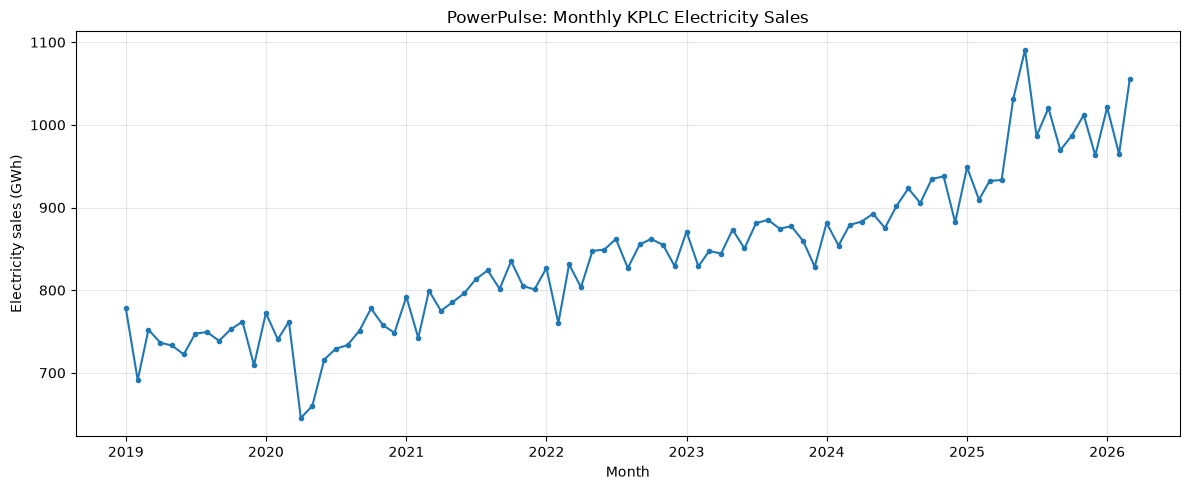


Average sales by calendar month:
             mean  median     std  count
month_num                               
1          861.42  848.82   88.24      8
2          811.41  794.45   94.18      8
3          857.40  839.34   99.81      8
4          802.98  803.56   95.90      7
5          831.79  847.54  120.12      7
6          842.93  849.10  126.11      7
7          845.91  862.05   90.15      7
8          851.77  826.82  100.39      7
9          842.28  855.34   83.66      7
10         860.95  862.00   82.55      7
11         855.49  854.70   93.20      7
12         823.01  828.34   83.80      7


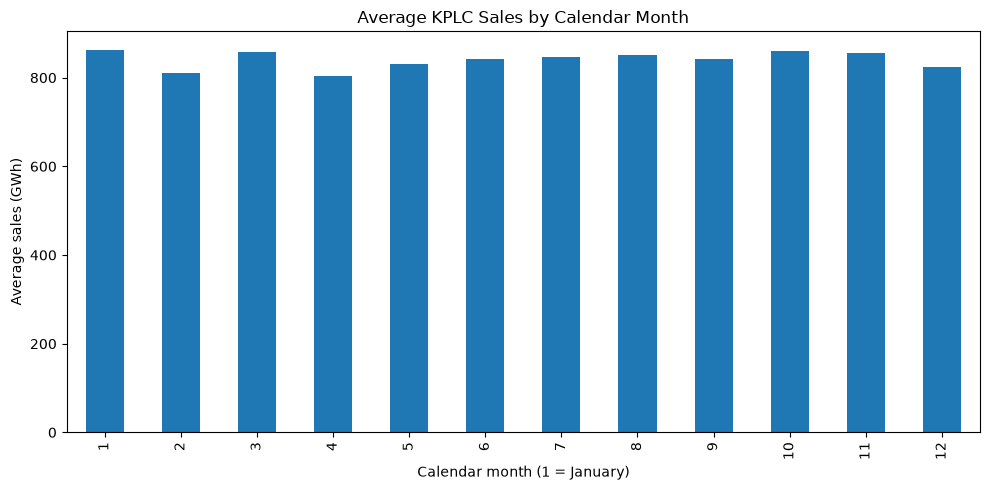


Annual sales summary:
         mean     min      max  count
year                                 
2019   739.40  691.32   778.12     12
2020   732.86  645.29   778.02     12
2021   797.54  742.34   835.08     12
2022   834.03  760.20   862.05     12
2023   860.08  828.34   885.17     12
2024   895.80  854.01   937.68     12
2025   981.96  909.50  1090.88     12
2026  1013.88  964.72  1055.74      3

Largest increases:
      date  kplc_sales_gwh  change_gwh
2025-05-01         1030.71       97.43
2026-03-01         1055.74       91.02
2022-03-01          831.21       71.01
2025-01-01          948.67       66.58
2020-01-01          772.37       63.15

Largest decreases:
      date  kplc_sales_gwh  change_gwh
2020-04-01          645.29     -116.61
2025-07-01          986.54     -104.34
2019-02-01          691.32      -86.80
2022-02-01          760.20      -66.60
2026-02-01          964.72      -56.45

EDA complete. Charts saved in the outputs folder.
Remember: historical candidate figures

In [6]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Load the combined working dataset
df = pd.read_csv("powerpulse_combined_WORKING_NOT_FINAL.csv")

df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date")

# Keep one row per month
assert df["date"].is_unique, "Duplicate monthly dates found!"
assert df["kplc_sales_gwh"].notna().all(), "Missing sales values found!"

# Create output folder
Path("outputs").mkdir(exist_ok=True)

# 1. Overall summary
print("--- POWERPULSE EDA ---")
print("Observations:", len(df))
print("Start:", df["date"].min())
print("End:", df["date"].max())
print("\nSales summary:")
print(df["kplc_sales_gwh"].describe())

# 2. Monthly sales trend
plt.figure(figsize=(12, 5))
plt.plot(
    df["date"],
    df["kplc_sales_gwh"],
    marker="o",
    markersize=3
)
plt.title("PowerPulse: Monthly KPLC Electricity Sales")
plt.xlabel("Month")
plt.ylabel("Electricity sales (GWh)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("outputs/monthly_sales_trend.png", dpi=150)
plt.show()

# 3. Average sales by calendar month
df["month_num"] = df["date"].dt.month
monthly_pattern = (
    df.groupby("month_num")["kplc_sales_gwh"]
    .agg(["mean", "median", "std", "count"])
    .round(2)
)

print("\nAverage sales by calendar month:")
print(monthly_pattern)

monthly_pattern["mean"].plot(
    kind="bar",
    figsize=(10, 5)
)
plt.title("Average KPLC Sales by Calendar Month")
plt.xlabel("Calendar month (1 = January)")
plt.ylabel("Average sales (GWh)")
plt.tight_layout()
plt.savefig("outputs/monthly_seasonality.png", dpi=150)
plt.show()

# 4. Annual summary
df["year"] = df["date"].dt.year
annual = (
    df.groupby("year")["kplc_sales_gwh"]
    .agg(["mean", "min", "max", "count"])
    .round(2)
)

print("\nAnnual sales summary:")
print(annual)

# 5. Largest month-to-month changes
df["change_gwh"] = df["kplc_sales_gwh"].diff()

print("\nLargest increases:")
print(
    df.nlargest(5, "change_gwh")[
        ["date", "kplc_sales_gwh", "change_gwh"]
    ].to_string(index=False)
)

print("\nLargest decreases:")
print(
    df.nsmallest(5, "change_gwh")[
        ["date", "kplc_sales_gwh", "change_gwh"]
    ].to_string(index=False)
)

print("\nEDA complete. Charts saved in the outputs folder.")
print("Remember: historical candidate figures still require verification.")

shows an apparent rise in monthly KPLC sales over the period, but there are also unusual jumps that we must investigate before forecasting.

The annual averages increase from 739.40 GWh in 2019 to 981.96 GWh in 2025. However, because the historical figures are still candidates and some recent months have unusual values, we should not yet interpret the entire rise as a confirmed real-world trend.

1. What your results tell us

2019 average sales

739.40 GWh

2025 average sales

981.96 GWh

The observed annual average increased by about 32.8% between 2019 and 2025. This is a descriptive comparison, not proof of the cause of the increase.

Three findings stand out:

An apparent upward trend: annual averages rise across most of the period.

Potentially unusual changes: April 2020 falls by 116.61 GWh, May 2025 rises by 97.43 GWh, and March 2026 rises by 91.02 GWh.

Incomplete 2026 data: only January–March are available, so the 2026 average is not comparable to a full-year average.

One particularly important concern is the jump in sales during May and June 2025. We previously identified these months as needing source and consistency checks. We must not smooth them or delete them just to make the forecast look better.

NEXT STEP: INVESTIGATE UNUSUAL OBSERVATIONS 


Before training models, let's produce a focused anomaly report. This will flag months for investigation without automatically treating them as errors.

In [7]:

import pandas as pd

df = pd.read_csv("powerpulse_combined_WORKING_NOT_FINAL.csv")
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

target = "kplc_sales_gwh"

# Month-to-month changes
df["change_gwh"] = df[target].diff()
df["change_pct"] = df[target].pct_change() * 100

# Same-month year-on-year comparison
df["year_on_year_change_gwh"] = df[target].diff(12)
df["year_on_year_change_pct"] = df[target].pct_change(12) * 100

# Flag large month-to-month changes for investigation.
# This is a review threshold, not a statistical test.
df["review_flag"] = df["change_pct"].abs() > 8

print("--- OBSERVATION REVIEW ---")
print("Flagged months:", df["review_flag"].sum())

print("\nMonths with changes above 8%:")
print(
    df.loc[
        df["review_flag"],
        ["date", target, "change_gwh", "change_pct"]
    ].round(2).to_string(index=False)
)

print("\nYear-on-year changes for the latest 15 records:")
print(
    df[
        [
            "date",
            target,
            "year_on_year_change_gwh",
            "year_on_year_change_pct"
        ]
    ].tail(15).round(2).to_string(index=False)
)

print("\nAverage sales by calendar month:")
df["calendar_month"] = df["date"].dt.month
print(
    df.groupby("calendar_month")[target]
    .agg(["mean", "median", "std", "count"])
    .round(2)
)

df.to_csv("powerpulse_anomaly_review.csv", index=False)
print("\nSaved: powerpulse_anomaly_review.csv")

--- OBSERVATION REVIEW ---
Flagged months: 10

Months with changes above 8%:
      date  kplc_sales_gwh  change_gwh  change_pct
2019-02-01          691.32      -86.80      -11.16
2019-03-01          752.26       60.94        8.82
2020-01-01          772.37       63.15        8.90
2020-04-01          645.29     -116.61      -15.31
2020-06-01          716.08       55.97        8.48
2022-02-01          760.20      -66.60       -8.06
2022-03-01          831.21       71.01        9.34
2025-05-01         1030.71       97.43       10.44
2025-07-01          986.54     -104.34       -9.56
2026-03-01         1055.74       91.02        9.43

Year-on-year changes for the latest 15 records:
      date  kplc_sales_gwh  year_on_year_change_gwh  year_on_year_change_pct
2025-01-01          948.67                    67.30                     7.64
2025-02-01          909.50                    55.49                     6.50
2025-03-01          932.30                    53.37                     6.07
2025-

C:\Users\HP\AppData\Local\Temp\ipykernel_33944\3466430131.py:29: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2).to_string(index=False)
C:\Users\HP\AppData\Local\Temp\ipykernel_33944\3466430131.py:41: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].tail(15).round(2).to_string(index=False)


What your results tell us

10 months exceed the 8% month-to-month change threshold. These are review flags, not automatic errors.

May and June 2025 need particular attention. Sales jump to 1,030.71 GWh and 1,090.88 GWh, with year-on-year increases of 15.49% and 24.63% respectively.

April 2020 has a large drop of 15.31%. We should check the source before deciding whether it reflects a real change or a data issue.

March 2026 rises by 9.43% month-to-month, but it is marked provisional in your current dataset, so treat it cautiously.

The 2022 and 2019 flags also need source checks. A sudden change alone does not justify deleting a value.

THIS WILL SHOW US WHICH SOURCE AND VERIFICATION DETAILS ARE AVAILABLE IN COMBINED FILE, SO WE CAN DECIDE WHICH RECORDS TO VERIFY FIRST.

In [8]:

import pandas as pd

df = pd.read_csv("powerpulse_combined_WORKING_NOT_FINAL.csv")
df["date"] = pd.to_datetime(df["date"])

print("COLUMNS IN THE DATASET:")
print(df.columns.tolist())

print("\nSOURCE / VERIFICATION COLUMNS:")
source_cols = [
    c for c in df.columns
    if any(word in c.lower() for word in
           ["source", "url", "report", "page", "table",
            "status", "verified", "note", "provisional"])
]
print(source_cols)

print("\nHISTORICAL CANDIDATES: 2019–2023")
historical = df[df["date"].dt.year.between(2019, 2023)]

cols = ["date", "kplc_sales_gwh"] + [
    c for c in source_cols if c in historical.columns
]
print(historical[cols].to_string(index=False))

print("\nCURRENT MASTER: 2024–2026")
current = df[df["date"].dt.year >= 2024]
cols = ["date", "kplc_sales_gwh"] + [
    c for c in source_cols if c in current.columns
]
print(current[cols].tail(8).to_string(index=False))

COLUMNS IN THE DATASET:
['date', 'kplc_sales_gwh', 'source_status', 'data_status', 'year', 'month', 'month_num', 'total_generation_gwh', 'imports_uganda_gwh', 'imports_ethiopia_gwh', 'imports_tanzania_gwh', 'total_imports_gwh', 'total_generation_and_imports_gwh', 'exports_uganda_gwh', 'exports_tanzania_gwh', 'total_exports_gwh', 'source', 'source_url', 'verification_status', 'verification_note']

SOURCE / VERIFICATION COLUMNS:
['source_status', 'data_status', 'source', 'source_url', 'verification_status', 'verification_note']

HISTORICAL CANDIDATES: 2019–2023
      date  kplc_sales_gwh                              source_status data_status source source_url verification_status verification_note
2019-01-01          778.12 Historical candidate - verify against KNBS   candidate    NaN        NaN                 NaN               NaN
2019-02-01          691.32 Historical candidate - verify against KNBS   candidate    NaN        NaN                 NaN               NaN
2019-03-01          

We have now confirmed an important distinction in PowerPulse:

2019–2023: the monthly values are still labelled candidate, with no source URLs or verification notes. They must not yet be treated as verified historical observations.

2024–2025: your existing master has KNBS source and verification information. The December 2025 record, for example, is marked verified.

January–March 2026: the values are marked verified_provisional, meaning they match the cited KNBS table but may be revised later.

The anomaly audit tells us which months deserve investigation, but it cannot establish whether those changes are errors.

NEXT ACTION ; CREATE A SOURCE-VERIFICATION COPY. 

In [9]:

import pandas as pd

input_file = "powerpulse_combined_WORKING_NOT_FINAL.csv"
output_file = "powerpulse_historical_verification_register.csv"

df = pd.read_csv(input_file)
df["date"] = pd.to_datetime(df["date"])

historical = df[df["date"].dt.year.between(2019, 2023)].copy()

historical["verification_status"] = "needs_source_check"
historical["verified_value_gwh"] = pd.NA
historical["report_title"] = ""
historical["report_url"] = ""
historical["table_reference"] = "Table 15(b)"
historical["verification_notes"] = ""

historical = historical[
    [
        "date",
        "kplc_sales_gwh",
        "verification_status",
        "verified_value_gwh",
        "report_title",
        "report_url",
        "table_reference",
        "verification_notes",
    ]
]

historical.to_csv(output_file, index=False)

print("Created:", output_file)
print("Historical months:", len(historical))
print("Status: candidates retained; no values automatically verified.")

Created: powerpulse_historical_verification_register.csv
Historical months: 60
Status: candidates retained; no values automatically verified.


this gives us a clean audit trail without accidentally labelling unverified values as confirmed.

Our immediate target is to establish a reliable monthly series from 2019 onward. After the source register is completed, we can freeze a verified modelling dataset, rerun the exploratory analysis, and then begin forecasting.

THE NEXT STEP IS TO VERIFY THE SOURCE FIGURES, NOT ADD MORE ANALYSIS OR START MODELLING PREMATURELY . WE SHOULD ALSO CHECK WHETHER THE FIGURES IN LATER KNBS REPORTS REVISE THOSE IN EARLIER REPORTS. 